[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/04-eda.ipynb)

# Exploratory Analysis

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Explore only the data you are allowed to learn from, and explain why.</li>
<li>Recognise heavy tails, seasonality and left-censoring in real data.</li>
<li>Read a relationship against its obvious confounder before believing a story.</li>
<li>Turn each finding into a concrete decision for the modelling steps.</li>
</ul>
</div>

**Prerequisites:** <a href="../03-cleaning/">Cleaning</a>. **Dataset:** Online Retail II. **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

We have clean data and a precise question. Before modelling, we *look*. Exploratory data analysis (EDA) is not a gallery of charts; it is a conversation with the data driven by questions, and each answer should change something we do next. For every chart on this page we will ask two things: **what does it show**, and **so what for the model**?

<div class="admonition warning">
<p class="admonition-title">The first rule of EDA: do not look at the data you will be tested on</p>
<p>Every pattern you notice quietly steers your decisions about features and models. If you explore the data you will later use to judge the result, the judgement is no longer honest: you have tuned to it by eye. We therefore explore <strong>only what happened before 1 June 2011</strong>, the date of our validation snapshot (the next-but-one page defines the splits properly). The validation and test periods stay unseen.</p>
</div>

In [2]:
cleaned = retail.clean_retail(load_retail())
EDA_END = retail.VALID_CUTOFF                                   # 2011-06-01: nothing at or after this date is used
s = cleaned.sales[cleaned.sales["invoice_date"] < EDA_END]
r = cleaned.returns[cleaned.returns["invoice_date"] < EDA_END]
inv = retail.invoices(s)
print(f"exploring {s['invoice_date'].min().date()} to {s['invoice_date'].max().date()}: {len(s):,} purchase lines, {inv['customer_id'].nunique():,} customers")

exploring 2009-12-01 to 2011-05-31: 536,710 purchase lines, 4,908 customers


## 1. How does the business move over time?

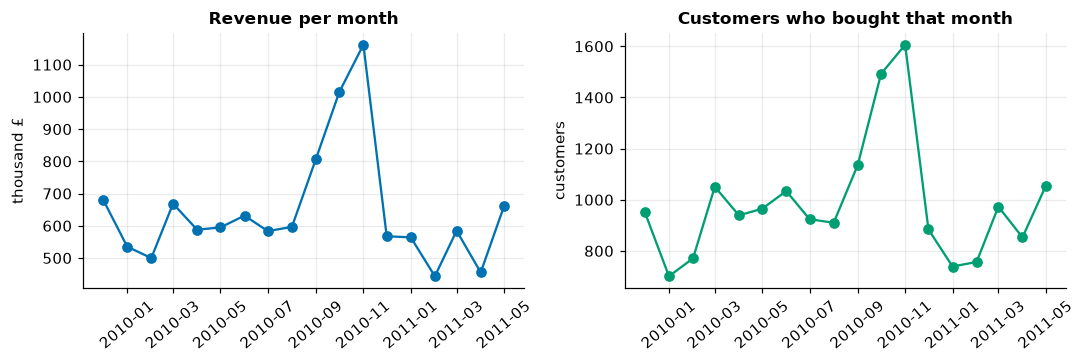

In [3]:
m = inv.set_index("date").resample("MS").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
a.plot(m.index, m["revenue"] / 1e3, marker="o", color=style.BLUE); a.set(title="Revenue per month", ylabel="thousand £")
b.plot(m.index, m["customers"], marker="o", color=style.GREEN); b.set(title="Customers who bought that month", ylabel="customers")
for ax in (a, b): ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

**What it shows.** A quiet baseline with a pronounced **autumn surge**: revenue and active customers both climb from September and peak in November (the shop sells gift-ware, so this is the Christmas build-up). Revenue then drops back sharply in December (the shop also shuts for eleven days around Christmas, as validation showed).

**So what.** Behaviour is seasonal, so *the same customer is more likely to buy in October than in April*. A snapshot's label will depend on the calendar, and any model must be judged on a window comparable to what it will face. We only see **one** autumn here; the test period contains another. Keep that in mind.

## 2. Who are the customers?

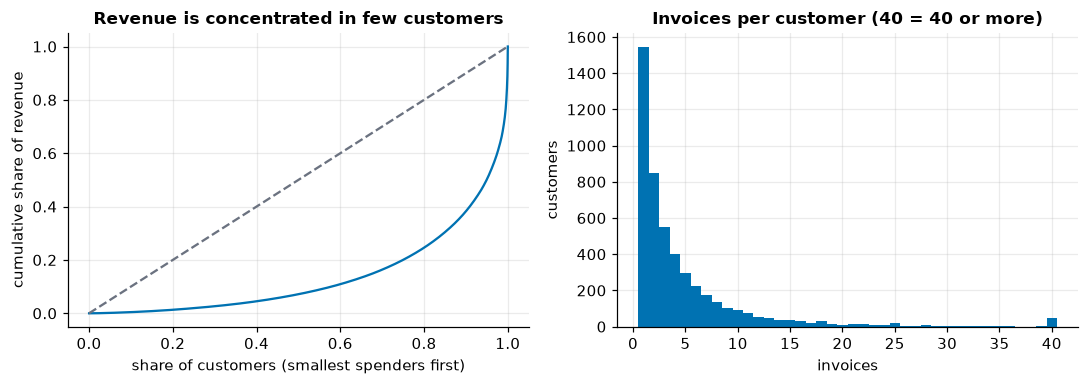

top 1% of customers    29.7%
top 10%                61.7%
top 20%                75.4%
bottom 50%              7.2%

customers with a single invoice: 31.5%;  median invoices per customer: 3;  most active: 234


In [4]:
rev = s.groupby("customer_id")["revenue"].sum().sort_values()
cum_share = rev.cumsum() / rev.sum()
x = np.arange(1, len(rev) + 1) / len(rev)
top = lambda p: rev.iloc[-int(len(rev) * p):].sum() / rev.sum()
shares = pd.Series({"top 1% of customers": top(0.01), "top 10%": top(0.10), "top 20%": top(0.20), "bottom 50%": cum_share.iloc[len(rev) // 2 - 1]})

n_inv = inv.groupby("customer_id").size()
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
a.plot(x, cum_share.to_numpy(), color=style.BLUE); a.plot([0, 1], [0, 1], color=style.GREY, ls="--")
a.set(title="Revenue is concentrated in few customers", xlabel="share of customers (smallest spenders first)", ylabel="cumulative share of revenue")
b.hist(n_inv.clip(upper=40), bins=np.arange(0.5, 41.5, 1), color=style.BLUE)
b.set(title="Invoices per customer (40 = 40 or more)", xlabel="invoices", ylabel="customers")
plt.tight_layout(); plt.show()
print((shares.map("{:.1%}".format)).to_string())
print(f"\ncustomers with a single invoice: {(n_inv == 1).mean():.1%};  median invoices per customer: {n_inv.median():.0f};  most active: {n_inv.max()}")

**What it shows.** Revenue is extremely concentrated: a tiny fraction of customers (largely wholesalers) account for a large share, while half the customers together contribute very little. And a large minority have bought **only once**, while a few have placed hundreds of orders.

**So what.**
- Raw spend and order counts are **heavy-tailed**: a mean is dragged around by a handful of giants. Expect to transform them (logs, ranks) or use models that do not care.
- The business question is skewed too: losing one top customer matters more than losing a hundred one-off buyers. That is why Page 1 defined success in *revenue protected*, not only in customers found.
- One-time buyers are a large and very different population. We will want to see whether the model treats them sensibly.

## 3. When during the day?

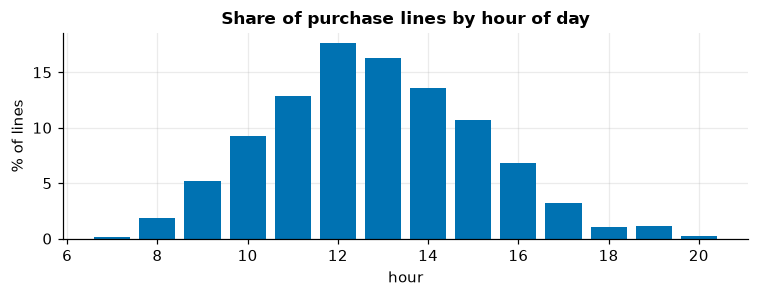

share of lines between 10:00 and 15:59: 80%


In [5]:
hour = s["invoice_date"].dt.hour.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(hour.index, hour.to_numpy() * 100, color=style.BLUE); ax.set(title="Share of purchase lines by hour of day", xlabel="hour", ylabel="% of lines")
plt.tight_layout(); plt.show()
print(f"share of lines between 10:00 and 15:59: {hour.loc[10:15].sum():.0%}")

**What it shows.** Orders arrive in office hours with a lunchtime peak, and the shop is closed on Saturdays. That is the signature of **business buyers**, not people shopping on a phone in the evening.

**So what.** Our "customers" are often small businesses, so ordering rhythms follow stock and season rather than whim. This is context for interpreting results, not a feature we need.

## 4. Where do customers come from?

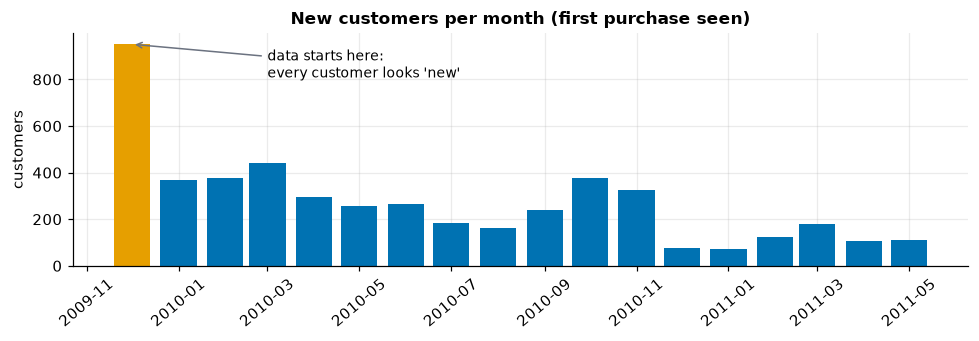

In [6]:
first = inv.groupby("customer_id")["date"].min().dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
cols = [style.ORANGE if i == 0 else style.BLUE for i in range(len(first))]
ax.bar(first.index.to_timestamp(), first.to_numpy(), width=24, color=cols)
ax.set(title="New customers per month (first purchase seen)", ylabel="customers"); ax.tick_params(axis="x", rotation=40)
ax.annotate("data starts here:\nevery customer looks 'new'", (first.index[0].to_timestamp(), first.iloc[0]), (pd.Timestamp("2010-03-01"), first.iloc[0] * 0.85), arrowprops=dict(arrowstyle="->", color=style.GREY), fontsize=9)
plt.tight_layout(); plt.show()

**What it shows.** The tall orange bar is not a launch day. It is the first month of the file, where *everyone who bought* is counted as new because we cannot see further back. This is **left-censoring**, a trap that appears whenever data starts at an arbitrary date. After that, new-customer arrivals slow, with a visible step down after November 2010 whose cause this data cannot tell us.

**So what.** We cannot know a customer's true tenure if they were already buying before December 2009, so any "customer age" feature is unreliable for the earliest customers. It is also why our snapshots begin a full year in.

## 5. What predicts buying again?

Now the question the model must answer. We build our training snapshots (the four dates before the validation cutoff, defined in the splitting page) and look at how the repurchase rate varies with simple behaviour.

16,925 customer-snapshots, repurchase rate 34.4%


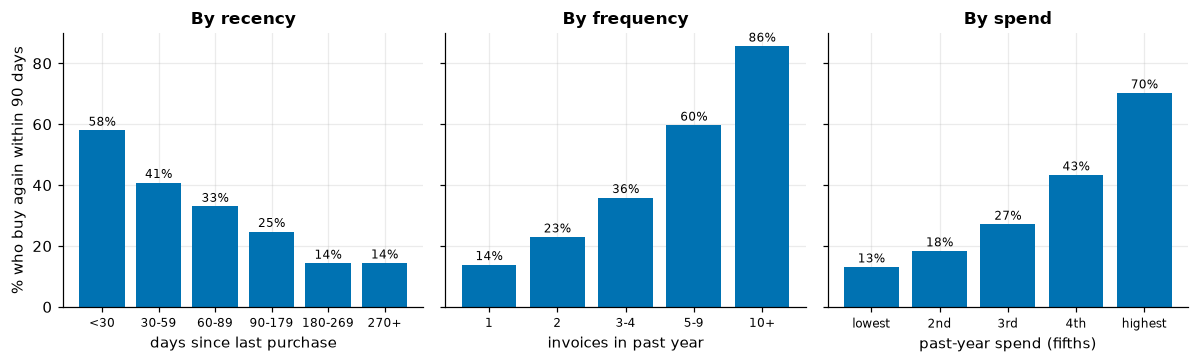

customers in each bin (recency): {'<30': 3980, '30-59': 2830, '60-89': 2562, '90-179': 4182, '180-269': 1906, '270+': 1465}


In [7]:
train = retail.make_snapshots(s, r, retail.TRAIN_CUTOFFS, features="full")
print(f"{len(train):,} customer-snapshots, repurchase rate {train['y'].mean():.1%}")

def rate_by(frame, col, bins, labels=None):
    g = frame.groupby(pd.cut(frame[col], bins, right=False, labels=labels), observed=True)["y"].agg(["size", "mean"])
    return g

rec = rate_by(train, "recency_days", [0, 30, 60, 90, 180, 270, 366], ["<30", "30-59", "60-89", "90-179", "180-269", "270+"])
frq = rate_by(train, "frequency", [1, 2, 3, 5, 10, 10_000], ["1", "2", "3-4", "5-9", "10+"])
mon = train.groupby(pd.qcut(train["monetary"], 5, labels=["lowest", "2nd", "3rd", "4th", "highest"]), observed=True)["y"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (tab, title, xl) in zip(axes, [(rec, "By recency", "days since last purchase"), (frq, "By frequency", "invoices in past year"), (mon, "By spend", "past-year spend (fifths)")]):
    ax.bar(tab.index.astype(str), tab["mean"] * 100, color=style.BLUE)
    for i, (rate, n) in enumerate(zip(tab["mean"], tab["size"])):
        ax.text(i, rate * 100 + 1.5, f"{rate:.0%}", ha="center", fontsize=8)
    ax.set(title=title, xlabel=xl); ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("% who buy again within 90 days")
plt.tight_layout(); plt.show()
print("customers in each bin (recency):", rec["size"].to_dict())

**What it shows.** All three relationships are strong and run in the direction you would expect: customers who bought recently, often, and in large amounts are far more likely to buy again, and the effect is large (a customer who bought in the last month is several times likelier to return than one silent for half a year).

**So what.** There is real signal in plain recency, frequency and spend, and a good model should find it easily. That also sets expectations: a model that merely rediscovers this will not be impressive. *The value of modelling is what it adds beyond these three numbers.*

But beware of reading each chart as if it stood alone.

In [8]:
train[["recency_days", "frequency", "monetary"]].corr(method="spearman").round(2)

,recency_days,frequency,monetary
recency_days,1.00,-0.52,-0.45
frequency,-0.52,1.00,0.82
monetary,-0.45,0.82,1.00


These three are **related to each other**: frequency and spend move almost together (0.82), and recency is moderately linked to both, since customers who buy often tend also to have bought recently. So the three charts above are partly *the same* effect seen three times, and we cannot tell from them which variable matters most. A model has to untangle that, and some models (like plain linear ones) get unstable when inputs are this correlated.

## 6. A trap: "returners buy more"

Do customers who have *returned* goods repurchase more or less often?

In [9]:
train["has_return"] = train["n_returns"] > 0
print("overall:", train.groupby("has_return")["y"].mean().round(3).rename({False: "no return", True: "has a return"}).to_dict())

by_freq = (train.assign(freq_band=pd.cut(train["frequency"], [1, 3, 6, 12, 10_000], right=False, labels=["1-2", "3-5", "6-11", "12+"]))
           .groupby(["freq_band", "has_return"], observed=True)["y"].agg(["mean", "size"]).unstack())
by_freq["mean"].round(3).rename(columns={False: "no return", True: "has a return"}).assign(**{"gap (pts)": lambda t: ((t["has a return"] - t["no return"]) * 100).round(1)})

overall: {'no return': 0.25, 'has a return': 0.496}


has_return,no return,has a return,gap (pts)
freq_band,,,
1-2,0.17,0.19,2.20
3-5,0.37,0.42,5.10
6-11,0.62,0.68,6.60
12+,0.78,0.89,11.90


**What it shows.** Overall, customers with a return are about twice as likely to buy again (roughly 50% against 25%). A tempting story: "returning an item means engagement" or even "let's encourage returns to retain customers".

But look at the second table, which compares customers of the **same** order frequency. The gap shrinks from about 25 points to between 2 and 12. Returns happen mostly to customers who order a lot, because they have more orders to return from, so *most of the raw difference was activity in disguise*: a **confounder**. Some gap remains among the heaviest buyers, so returns are not pure noise either; we cannot separate that from other kinds of engagement with this data.

**So what.** (1) A feature can be useful for prediction while meaning nothing causal, and that is fine for ranking, but we must not read it as advice. (2) Always check an interesting relationship against the obvious confounder before believing a story.

## 7. Does country matter?

In [10]:
country = train.assign(group=np.where(train["is_uk"] == 1, "UK", "outside UK")).groupby("group")["y"].agg(["size", "mean"])
country["mean"] = country["mean"].map("{:.1%}".format)
country.rename(columns={"size": "customer-snapshots", "mean": "buys again"})

,customer-snapshots,buys again
group,,
UK,15570,34.0%
outside UK,1355,39.6%


A modest difference: customers outside the UK buy again somewhat more often (about six points), but they are under a tenth of the data, so the estimate is noisy, and it may simply reflect that overseas buyers are larger wholesalers (another possible confounder). It is a candidate feature, and a natural one to check in a fairness-style review later.

## 8. Is the target stable over time?

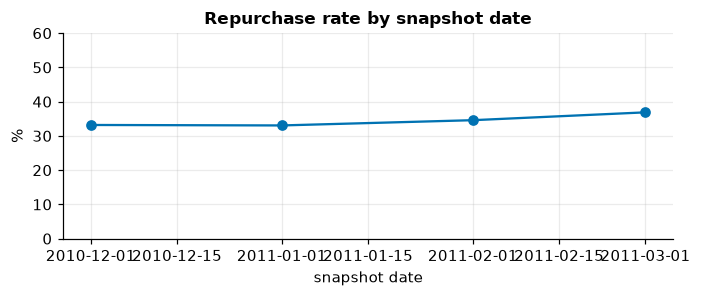

,customers,repurchase rate
cutoff,,
2010-12-01,4239,33.2%
2011-01-01,4205,33.1%
2011-02-01,4221,34.6%
2011-03-01,4260,36.9%


In [11]:
tbl = (train.groupby("cutoff")["y"].agg(["size", "mean"]).rename(columns={"size": "customers", "mean": "repurchase rate"}))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(tbl.index, tbl["repurchase rate"] * 100, marker="o", color=style.BLUE); ax.set(ylim=(0, 60), title="Repurchase rate by snapshot date", ylabel="%", xlabel="snapshot date")
plt.tight_layout(); plt.show()
tbl.assign(**{"repurchase rate": tbl["repurchase rate"].map("{:.1%}".format)})

Over the training snapshots the rate drifts up a little (from about a third to over a third). Given the seasonality in section 1, that is **not** a promise it stays this steady: the label windows of later snapshots reach into the autumn peak. We will see on the splitting page how much that matters.

<div class="admonition tip">
<p class="admonition-title">What EDA told us to do</p>
<ul>
<li><strong>Heavy tails</strong> in spend and order counts: transform them or use tree-based models.</li>
<li><strong>Recency, frequency and spend</strong> carry strong, correlated signal: set a baseline from them first, and judge any model by what it adds beyond them.</li>
<li><strong>Seasonality</strong>: judge models on time-ordered windows, never shuffled ones, and expect the base rate to move.</li>
<li><strong>Left-censoring</strong>: do not trust "customer age" for early customers; start snapshots a year in.</li>
<li><strong>Confounding</strong>: read features as predictors, not causes.</li>
<li>Judge success in <strong>revenue</strong> as well as counts, because spend is so concentrated.</li>
</ul>
</div>

## Check yourself

<details class="question">
<summary>1. Why do we explore only data before 1 June 2011, even though we have all of it?</summary>

Because anything we notice influences what we build. If we explored the validation and test periods, our features and models would be tuned, consciously or not, to patterns we later claim to be "discovering" on unseen data. Holding the future back is what keeps the final score honest.

</details>

<details class="question">
<summary>2. The 'new customers' chart has a huge first bar. Is that a successful launch?</summary>

No, it is **left-censoring**: the file begins in December 2009, so everyone who buys that month looks new even if they have been customers for years. Any time a dataset starts at an arbitrary date, the earliest period will look unusual for reasons that have nothing to do with the business.

</details>

<details class="question">
<summary>3. Customers with a return are much likelier to buy again, but much less so once we compare customers with similar order counts. What should you conclude about <em>encouraging</em> returns?</summary>

Nothing causal. Most of the raw gap was produced by activity: heavy buyers return more because they buy more. The relationship is useful for *prediction* (it correlates with engagement) but it is not evidence that returns *cause* loyalty, and it says nothing about what would happen if the shop pushed customers to return things.

</details>

## Exercise

<details class="question">
<summary>What share of the revenue in the exploration window comes from customers who bought <em>exactly once</em>? Guess first. Then compute it, and say what it implies for the model.</summary>

```python
once = n_inv[n_inv == 1].index
share = s.loc[s["customer_id"].isin(once), "revenue"].sum() / s["revenue"].sum()
print(f"{share:.1%} of revenue comes from one-time buyers ({len(once) / len(n_inv):.0%} of customers)")
```

One-time buyers are about 31% of *customers* but only about 5% of *revenue*. That means a model that is mediocre on them but good on repeat buyers still protects most of the money, and it argues for reporting results **separately for new and established customers** rather than one blended number.

</details>

## Recap

- Ask a question of every chart, and ask **so what for the model?** of every answer.
- Explore only the data you are allowed to learn from; keep validation and test unseen.
- Heavy tails, seasonality and left-censoring are the usual surprises; look for them on purpose.
- Recency, frequency and spend carry strong but **correlated** signal; the model's job is to add value beyond them.
- Check an exciting relationship against the obvious confounder before believing it.

**Next:** *Splitting strategy*, where we decide exactly how to divide time into training, validation and test, and see what happens when we get it wrong.